# Visualization

可视化

In [1]:
import os, sys, itertools
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))
from hw2vec.config import Config
from hw2vec.hw2graph import *
from tqdm import tqdm

/home/heyiran/.conda/envs/HWsim/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
dir = ['--yaml_path', '../config/example_gnn4ip.yaml', \
    #    '--raw_dataset_path', '../../bigcreate/newdatas', \
    #    '--data_pkl_path', 'pkl/dfg_ip_rt291.pkl', \
        '--graph_type', 'DFG']
# cfg = Config(sys.argv[1:])
cfg = Config(dir)

In [3]:
cfg.num_feature_dim = 17

In [4]:
# dataset = torch.load("Reduced-DFG-with_big.pt")
dataset = torch.load("Reduced-DFG.pt")

In [5]:
len(dataset)

248

In [6]:
len(trainset)

NameError: name 'trainset' is not defined

In [ ]:
len(testset)

NameError: name 'testset' is not defined

In [ ]:
# train_loader = DataLoader(trainset, shuffle=True, batch_size=cfg.batch_size)
train_loader = DataLoader(dataset, shuffle=True, batch_size=cfg.batch_size)

In [ ]:
model = GRAPH2VEC(cfg)
convs = [
    GRAPH_CONV("gcn", 17, cfg.hidden),#前者是标签数量，后者是隐藏层
    GRAPH_CONV("gcn", cfg.hidden, cfg.hidden),
    GRAPH_CONV("gcn", cfg.hidden, cfg.hidden)
]
model.set_graph_conv(convs)

pool = GRAPH_POOL("sagpool", cfg.hidden, cfg.poolratio)
model.set_graph_pool(pool)

readout = GRAPH_READOUT("mean")
model.set_graph_readout(readout)

output = nn.Linear(cfg.hidden, cfg.embed_dim)
model.set_output_layer(output)

# output = nn.Linear(cfg.hidden, cfg.embed_dim)
# model.set_node_output_layer(output)

In [ ]:
model.load_state_dict(torch.load("triplet_model_notestset.pt"))

RuntimeError: Error(s) in loading state_dict for GRAPH2VEC:
	Missing key(s) in state_dict: "pool1.graph_pool.select.weight". 

In [ ]:
cfg.device = 'cuda'
model.to(cfg.device)
trainer = PairwiseGraphTrainer(cfg)
trainer.build(model)

In [ ]:
cfg.trainer = 'triplet'
trainer.triplet_train(train_loader)

  0%|          | 0/100 [00:00<?, ?it/s]


IndexError: Dimension out of range (expected to be in range of [-1, 0], but got -2)

## 可视化

In [ ]:
import umap
import matplotlib.pyplot as plt
from cycler import cycler

需要先获取所有样本的特征，得按batch收集一下吧

In [ ]:
embeddings = []
labels = []

In [ ]:
with torch.no_grad():
    trainer.model.eval()

    for data in train_loader:
        data.to(cfg.device)
        label = data.label
        # print(label.type)
        embed_x, _ = trainer.model.embed_graph(data.x, data.edge_index, data.batch)
        embed_x = trainer.model.mlp(embed_x)
        embeddings.append(embed_x)
        labels.append(label)

IndexError: Dimension out of range (expected to be in range of [-1, 0], but got -2)

In [ ]:
embeddingszz = embeddings[0]
for e in embeddings[1:]:
    embeddingszz = torch.cat([embeddingszz, e])

IndexError: list index out of range

In [ ]:
embeddingszz.shape

torch.Size([248, 128])

In [ ]:
labelszz = labels[0]
for e in labels[1:]:
    labelszz = torch.cat([labelszz, e])

In [ ]:
labelszz.shape

torch.Size([248])

得把张量从显卡移到CPU，再转为`NumPy`类型

In [ ]:
embeddings = embeddingszz.cpu().numpy()

In [ ]:
embeddings.shape

(248, 128)

In [ ]:
labels = labelszz.cpu().numpy()

In [ ]:
labels.shape

(248,)

## 保存

给可视化网站用

https://projector.tensorflow.org

In [ ]:
np.savetxt("embeddings.tsv", embeddings, delimiter='\t')

In [ ]:
np.savetxt("labels.tsv", labels, delimiter='\t')

## 调用`UMAP`

In [ ]:
reducer = umap.UMAP()
umap_embeddings = reducer.fit_transform(embeddings)

ValueError: Expected 2D array, got 1D array instead:
array=[].
Reshape your data either using array.reshape(-1, 1) if your data has a single feature or array.reshape(1, -1) if it contains a single sample.

In [ ]:
reducer = umap.UMAP(random_state=42, min_dist=0.89, metric='cosine')
reducer.fit(embeddings)
umap_embeddings = reducer.transform(embeddings)

ValueError: Expected 2D array, got 1D array instead:
array=[].
Reshape your data either using array.reshape(-1, 1) if your data has a single feature or array.reshape(1, -1) if it contains a single sample.

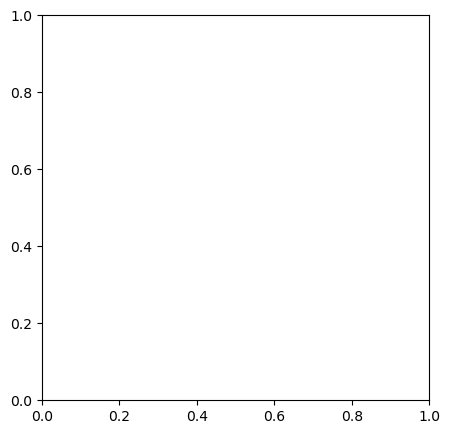

In [ ]:
label_set = np.unique(labels)
num_classes = len(label_set)
# print(num_classes, label_set)
plt.figure(figsize=(5, 5))
plt.gca().set_prop_cycle(
    cycler(
        "color", [plt.cm.nipy_spectral(i) for i in np.linspace(0, 0.9, num_classes)]
    )
)
for i in range(num_classes):
    idx = labels == label_set[i]
    # print(idx)
    plt.plot(umap_embeddings[idx, 0], umap_embeddings[idx, 1], ".", markersize=1)
# plt.colorbar(boundaries=np.arange(10)-0.5).set_ticks(np.arange(num_classes))
plt.show()

虽然效果不如PML的栗子那么明显，但是和umap官网的样例其实是很相似的，调一调图，是可以放论文里的吧？

之后可以看怎么加个图例

In [ ]:
# plt.scatter(umap_embeddings[:, 0], umap_embeddings[:, 1], s=10, c=labels, marker='.', cmap='Spectral', alpha=1)
# plt.scatter(umap_embeddings[:, 0], umap_embeddings[:, 1], s=50, c=labels, marker='.', cmap='rainbow', alpha=0.5)  # hsv
plt.scatter(umap_embeddings[:, 0], umap_embeddings[:, 1], s=10, c=labels, marker='.', cmap='rainbow', alpha=1) 
plt.gca().set_aspect('equal', 'datalim')
plt.colorbar(boundaries=np.arange(10)-0.5).set_ticks(np.arange(num_classes))
# plt.title('UMAP projection of the Digits dataset', fontsize=24)

NameError: name 'umap_embeddings' is not defined

好多参数不知道是啥意思，论文中确定要用的话还可以再尝试美观一下。

现在足够说明度量学习的有效性了吧